# Benign and Malignant Breast Histopathology Image Classification: A Comparative Study of Classical Machine Learning, Pretrained CNNs and Vision Transformers

## Introduction

In this study, I compare classical machine-learning methods, pretrained convolutional neural networks (CNNs) and Vision Transformers for classifying breast histopathology images as benign or malignant. I use the 100X subset of BreakHis so that the models are assessed on images captured at the same magnification.

The classical models are Logistic Regression, Random Forest, SVM and XGBoost, trained on colour and texture descriptors. I also fine-tune three pretrained CNNs (MobileNetV2, ResNet50 and EfficientNetB0) and three Vision Transformers (ViT Base, Swin Tiny and DeiT Small). I compare their predictions on the same test set, paying attention to both overall performance and errors within each class.

## 1. Preparing the computational environment

I import the libraries needed for image processing, model training and evaluation. NumPy and Pandas handle the data, while scikit-image provides the handcrafted features used by the classical models. I use scikit-learn and XGBoost for the traditional classifiers and PyTorch with `timm` for the pretrained image models. Matplotlib and Seaborn are used to examine the data and present the results.

I set the random seed to 42 to reduce variation between runs. The models were trained using CUDA. Although fixing the seed improves reproducibility, the results may still vary with hardware, library versions and some GPU operations.

In [1]:
%pip install -q timm xgboost scikit-image seaborn --upgrade

import os
import sys
import glob
import time
import random
import zipfile
import warnings
from pathlib import Path
from dataclasses import dataclass, field
from typing import List, Dict, Tuple, Optional, Callable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

from skimage.io import imread
from skimage.color import rgb2gray
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, roc_auc_score,
    roc_curve, confusion_matrix, classification_report,
)
from xgboost import XGBClassifier

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.7/13.7 MB 51.3 MB/s eta 0:00:00
Device: cuda


## 2. Locating the dataset and defining the experiment

I load the BreakHis images from the dataset directory in Google Drive. The code checks for the expected magnification and class folders before proceeding. In this run, the dataset was already available, so it did not need to be extracted again.

I first include all four magnifications when checking the files, but I set `MAGNIFICATION = '100X'` for the classification experiments. This keeps the subsequent analysis focused on a single magnification rather than combining images with different levels of detail.

In [2]:
def mount_google_drive() -> bool:
    """Mount Google Drive if running on Colab. Returns True if mounted."""
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        return True
    except ImportError:
        print('Not running on Colab — skipping Drive mount.')
        return False


def find_data_root(
    search_dir: Path, magnifications: List[str], classes: Optional[List[str]] = None
) -> Optional[Path]:
    """
    Recursively search `search_dir` for a folder that directly contains all
    `magnifications` as subfolders (e.g. 40X/100X/200X/400X).

    If `classes` is given (e.g. ['benign', 'malignant']), a candidate is only
    accepted if its magnification subfolders themselves contain those class
    subfolders (case-insensitive). This disambiguates datasets that have both a
    binary (`classificacao_binaria`) and multiclass (`classificacao_multiclasse`)
    variant sharing the same magnification folder names.
    """
    search_dir = Path(search_dir)
    if not search_dir.is_dir():
        return None
    for root, dirs, _ in os.walk(search_dir):
        if not all(mag in dirs for mag in magnifications):
            continue
        root_path = Path(root)
        if classes is None:
            return root_path
        matches_classes = True
        for mag in magnifications:
            sub_names = {d.lower() for d in os.listdir(root_path / mag)
                         if (root_path / mag / d).is_dir()}
            if not all(cls.lower() in sub_names for cls in classes):
                matches_classes = False
                break
        if matches_classes:
            return root_path
    return None


def ensure_dataset_extracted(
    base_dir: str,
    zip_filename: str = 'Breast_hist.zip',
    extract_subdir: str = 'data',
    magnifications: List[str] = ('40X', '100X', '200X', '400X'),
    classes: Optional[List[str]] = None,
) -> Path:
    """
    Locate (or extract) the BreakHis dataset and return the folder that directly
    contains the magnification subfolders (40X/100X/200X/400X), verified to hold
    the given `classes` (e.g. binary benign/malignant, not multiclass subtypes).

    Resolution order:
    1. If `base_dir` itself already contains (or contains nested within it) a
       matching folder, use that directly — no extraction needed.
    2. Otherwise, if a zip file exists at `base_dir/zip_filename`, extract it to
       `base_dir/extract_subdir` and search there.
    3. Raise `FileNotFoundError` if neither is found.
    """
    base_dir = Path(base_dir)

    data_root = find_data_root(base_dir, magnifications, classes)
    if data_root is not None:
        print(f'Found existing data root: {data_root}')
        return data_root

    zip_path = base_dir / zip_filename
    extract_dir = base_dir / extract_subdir

    if zip_path.exists():
        extract_dir.mkdir(parents=True, exist_ok=True)
        print(f'Extracting {zip_path} ...')
        with zipfile.ZipFile(zip_path, 'r') as zf:
            zf.extractall(extract_dir)
        print(f'Extracted to: {extract_dir}')
        data_root = find_data_root(extract_dir, magnifications, classes)
        if data_root is not None:
            return data_root

    raise FileNotFoundError(
        f'Could not locate a folder containing {magnifications}'
        + (f' with class subfolders {classes}' if classes else '')
        + f' under {base_dir}, and no usable zip file was found at {zip_path}. '
        f'Update BASE_DIR to point at (or above) the extracted dataset, or place '
        f'the zip at that path.'
    )


def load_dataset(base_dir: str, zip_filename: str = 'Breast_hist.zip', classes: Optional[List[str]] = None) -> Path:
    """High-level convenience wrapper: mount Drive (if on Colab) + locate/extract dataset."""
    mount_google_drive()
    return ensure_dataset_extracted(base_dir=base_dir, zip_filename=zip_filename, classes=classes)


# ---- Configuration ----
# Point this at (or above) wherever the BreakHis data lives on your Drive.
# It can be the exact folder containing 40X/100X/200X/400X, a parent folder,
# or a folder containing Breast_hist.zip — load_dataset() will figure it out.
BASE_DIR = '/content/drive/MyDrive/DATASET MASTERS THESIS/Breast Cancer'
MAGNIFICATIONS = ['40X', '100X', '200X', '400X']
CLASSES = ['benign', 'malignant']
MAGNIFICATION = '100X'  # working magnification used for modelling stages

DATA_ROOT = load_dataset(BASE_DIR, classes=CLASSES)
print('Data root:', DATA_ROOT)

Mounted at /content/drive
Found existing data root: /content/drive/MyDrive/DATASET MASTERS THESIS/Breast Cancer/BreakHis - Breast Cancer Histopathological Database/dataset_cancer_v1/dataset_cancer_v1/classificacao_binaria
Data root: /content/drive/MyDrive/DATASET MASTERS THESIS/Breast Cancer/BreakHis - Breast Cancer Histopathological Database/dataset_cancer_v1/dataset_cancer_v1/classificacao_binaria


## 3. Counting images by magnification and class

Before selecting the modelling images, I count the files in each magnification and class. This gives me an overview of the available data and helps establish whether the classes are evenly represented.

The counts refer to files found in the dataset folders. They do not establish whether visually identical images or images from the same patient are present more than once.

magnification  benign  malignant  total
          40X     641       1370   2011
         100X     644       1437   2081
         200X     623       1390   2013
         400X     588       1232   1820


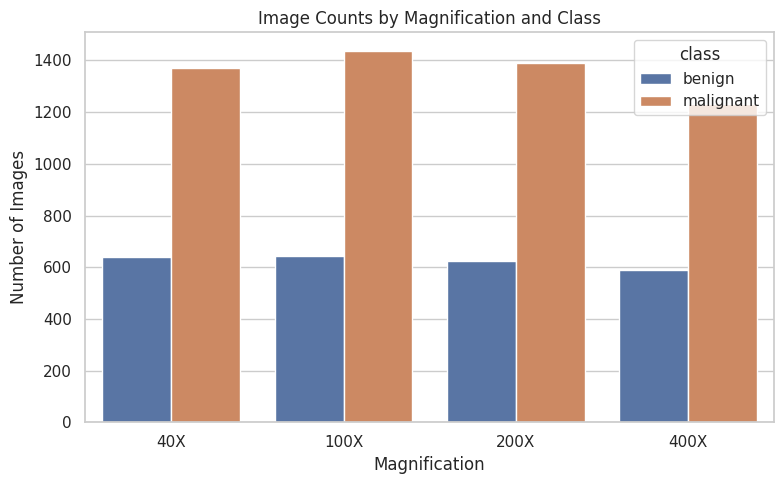

In [3]:
def resolve_class_dir(magnification_dir: Path, class_name: str) -> Optional[Path]:
    """Find a subfolder of `magnification_dir` matching `class_name`, case-insensitively."""
    if not magnification_dir.is_dir():
        return None
    for d in magnification_dir.iterdir():
        if d.is_dir() and d.name.lower() == class_name.lower():
            return d
    return None


def find_images(
    folder: Path, extensions: Tuple[str, ...] = ('png', 'jpg', 'jpeg', 'tif', 'tiff', 'bmp')
) -> List[Path]:
    """
    Recursively find image files under `folder` (handles nested patient-ID/tumor-type
    subfolders, as in the original BreakHis layout), case-insensitive extensions.
    """
    if folder is None or not folder.is_dir():
        return []
    found = set()
    for ext in extensions:
        found.update(folder.rglob(f'*.{ext}'))
        found.update(folder.rglob(f'*.{ext.upper()}'))
    return sorted(found)


def count_images_per_magnification(
    data_root: Path, magnifications: List[str], classes: List[str]
) -> pd.DataFrame:
    """Count image files per (magnification, class) combination (recursive, multi-extension)."""
    rows = []
    for mag in magnifications:
        mag_dir = data_root / mag
        row = {'magnification': mag}
        total = 0
        for cls in classes:
            cls_dir = resolve_class_dir(mag_dir, cls)
            n = len(find_images(cls_dir))
            row[cls] = n
            total += n
        row['total'] = total
        rows.append(row)
    return pd.DataFrame(rows)


def plot_image_counts(counts_df: pd.DataFrame, classes: List[str]) -> None:
    """Grouped bar chart of image counts per magnification and class."""
    melted = counts_df.melt(id_vars='magnification', value_vars=classes,
                             var_name='class', value_name='count')
    plt.figure(figsize=(8, 5))
    sns.barplot(data=melted, x='magnification', y='count', hue='class')
    plt.title('Image Counts by Magnification and Class')
    plt.ylabel('Number of Images')
    plt.xlabel('Magnification')
    plt.tight_layout()
    plt.show()


counts_df = count_images_per_magnification(DATA_ROOT, MAGNIFICATIONS, CLASSES)
print(counts_df.to_string(index=False))

if counts_df['total'].sum() == 0:
    print('\nNo images found. Inspecting folder structure for debugging:')
    for mag in MAGNIFICATIONS:
        mag_dir = DATA_ROOT / mag
        if mag_dir.is_dir():
            print(f'{mag_dir} ->', [d.name for d in mag_dir.iterdir()][:10])
        else:
            print(f'{mag_dir} does not exist')
else:
    plot_image_counts(counts_df, CLASSES)

### Interpretation of image counts

I found 7,925 image files across the four magnifications. The 100X category contains the largest number (2,081), followed by 200X (2,013), 40X (2,011) and 400X (1,820).

Malignant images outnumber benign images at every magnification. At 100X, there are 1,437 malignant images compared with 644 benign images. This imbalance is important when evaluating the classifiers: a high accuracy score alone may conceal poorer recognition of the smaller benign class. I therefore examine class-specific recall and confusion matrices as well as the overall scores.

## 4. Building the image index and selecting 100X images

I create a dataframe containing the file path, class label and magnification of each image. The dataframe serves as an index; the actual image data are read later during feature extraction and model training.

I then filter this dataframe to retain only the 100X images. The resulting subset is used throughout the experiment, including the exploratory analysis and the train, validation and test partitions.

In [4]:
def build_image_dataframe(
    data_root: Path, magnifications: List[str], classes: List[str]
) -> pd.DataFrame:
    """Build a DataFrame with columns [path, label, magnification] for all images."""
    records = []
    for mag in magnifications:
        mag_dir = data_root / mag
        for cls in classes:
            cls_dir = resolve_class_dir(mag_dir, cls)
            if cls_dir is None:
                print(f'Missing folder for class "{cls}" under {mag_dir}')
                continue
            for p in find_images(cls_dir):
                records.append({'path': str(p), 'label': cls, 'magnification': mag})
    return pd.DataFrame(records)


master_df = build_image_dataframe(DATA_ROOT, MAGNIFICATIONS, CLASSES)
print('Total images (all magnifications):', len(master_df))
print(master_df.groupby(['magnification', 'label']).size())

# Working subset for modelling
df = master_df[master_df['magnification'] == MAGNIFICATION].reset_index(drop=True)
print(f'\nWorking subset ({MAGNIFICATION}):', len(df), 'images')
print(df['label'].value_counts())

Total images (all magnifications): 7925
magnification  label    
100X           benign        644
               malignant    1437
200X           benign        623
               malignant    1390
400X           benign        588
               malignant    1232
40X            benign        641
               malignant    1370
dtype: int64

Working subset (100X): 2081 images
label
malignant    1437
benign        644
Name: count, dtype: int64


### Interpretation of the selected dataset

The working dataset contains 2,081 images, of which 1,437 (69.1%) are malignant and 644 (30.9%) are benign. A classifier that always predicted the majority class would therefore obtain approximately 69.1% accuracy, despite failing to identify any benign images.

This illustrates why I cannot judge model performance using accuracy alone. The results also need to be considered in light of possible similarities between images, which are not assessed by the file-indexing procedure.

## 5. Exploring the images before modelling

I display examples from the benign and malignant folders at each magnification to examine the appearance of the tissue and staining. I also plot the class distribution for the selected 100X images.

These examples help me understand the dataset visually, but a few sample images are not enough to establish reliable differences between the two classes. The class distribution, however, confirms the imbalance observed in the image counts.

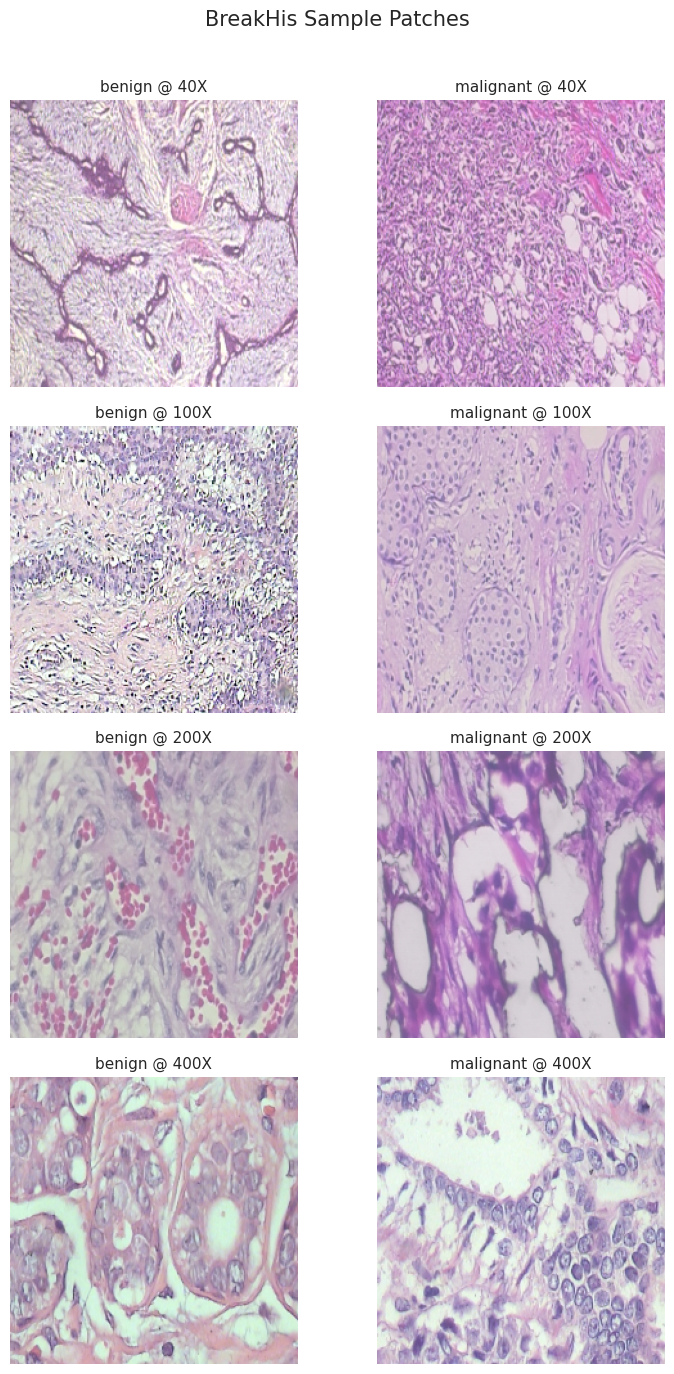

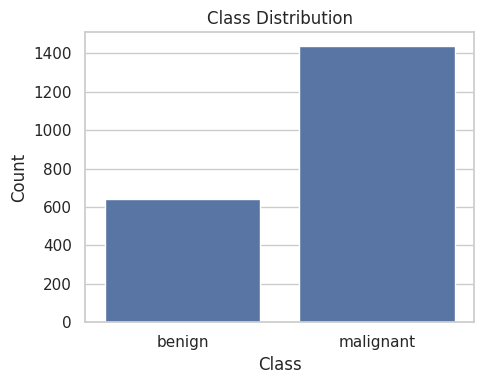

In [5]:
def plot_sample_grid(
    data_root: Path, magnifications: List[str], classes: List[str], seed: int = 42
) -> None:
    """Plot one random sample image per (magnification, class) combination."""
    rng = random.Random(seed)
    fig, axes = plt.subplots(len(magnifications), len(classes), figsize=(4 * len(classes), 3.5 * len(magnifications)))
    for i, mag in enumerate(magnifications):
        mag_dir = data_root / mag
        for j, cls in enumerate(classes):
            cls_dir = resolve_class_dir(mag_dir, cls)
            images = find_images(cls_dir)
            ax = axes[i, j]
            if not images:
                ax.set_visible(False)
                continue
            img = Image.open(rng.choice(images))
            ax.imshow(img)
            ax.axis('off')
            ax.set_title(f'{cls} @ {mag}', fontsize=11)
    plt.suptitle('BreakHis Sample Patches', fontsize=15)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()


def plot_class_distribution(df: pd.DataFrame, label_col: str = 'label') -> None:
    """Bar chart of class distribution for a given DataFrame."""
    plt.figure(figsize=(5, 4))
    sns.countplot(data=df, x=label_col, order=sorted(df[label_col].unique()))
    plt.title('Class Distribution')
    plt.xlabel('Class')
    plt.ylabel('Count')
    plt.tight_layout()
    plt.show()


plot_sample_grid(DATA_ROOT, MAGNIFICATIONS, CLASSES, seed=RANDOM_STATE)
plot_class_distribution(df)

### Examining image dimensions, brightness and colour

I examine a reproducible sample of up to 200 images from the 100X subset. For each image, I record its dimensions, aspect ratio and average grayscale brightness. I also calculate the mean intensity of the red, green and blue channels.

The plots allow me to check whether image dimensions are consistent and whether brightness or colour differs noticeably between the classes. Since the sample is not stratified, these findings describe the sampled images rather than the full dataset.

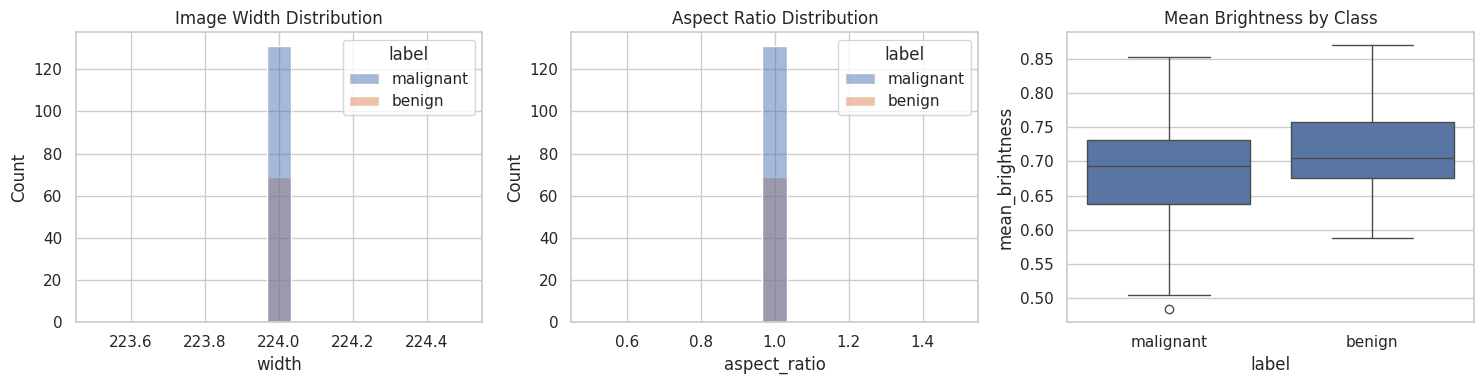

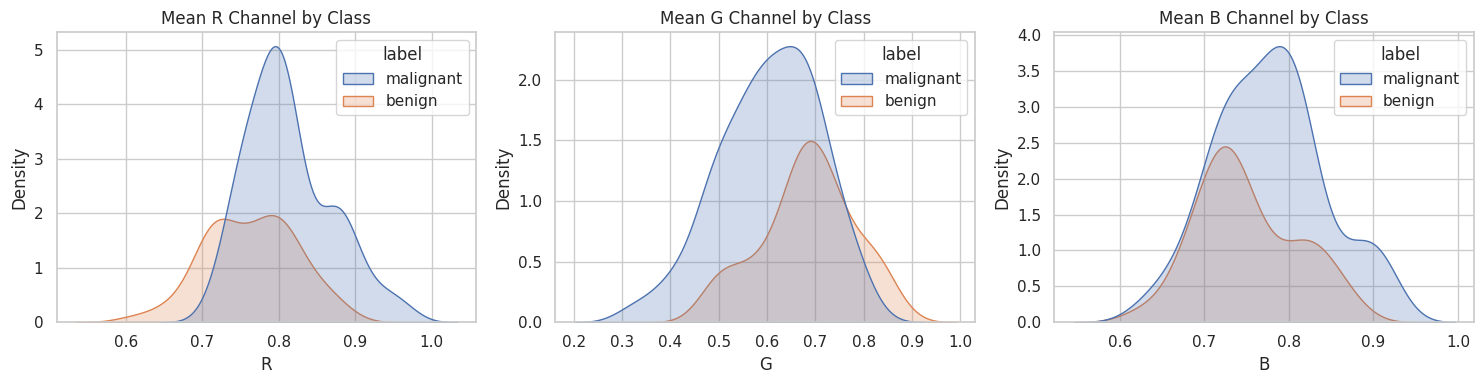

In [6]:
def analyze_image_properties(df: pd.DataFrame, sample_size: int = 200, seed: int = 42) -> pd.DataFrame:
    """Sample images and compute basic properties: width, height, aspect ratio, mean brightness."""
    sample = df.sample(n=min(sample_size, len(df)), random_state=seed)
    rows = []
    for _, r in sample.iterrows():
        img = Image.open(r['path'])
        w, h = img.size
        arr = np.array(img.convert('L'), dtype=np.float32) / 255.0
        rows.append({
            'label': r['label'], 'width': w, 'height': h,
            'aspect_ratio': w / h, 'mean_brightness': arr.mean(),
        })
    return pd.DataFrame(rows)


def plot_image_properties(props_df: pd.DataFrame) -> None:
    """Visualize distributions of image dimensions and brightness by class."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    sns.histplot(data=props_df, x='width', hue='label', bins=15, ax=axes[0])
    axes[0].set_title('Image Width Distribution')
    sns.histplot(data=props_df, x='aspect_ratio', hue='label', bins=15, ax=axes[1])
    axes[1].set_title('Aspect Ratio Distribution')
    sns.boxplot(data=props_df, x='label', y='mean_brightness', ax=axes[2])
    axes[2].set_title('Mean Brightness by Class')
    plt.tight_layout()
    plt.show()


def plot_color_channel_distributions(df: pd.DataFrame, sample_size: int = 200, seed: int = 42) -> None:
    """Plot mean R/G/B channel value distributions, split by class."""
    sample = df.sample(n=min(sample_size, len(df)), random_state=seed)
    records = []
    for _, r in sample.iterrows():
        img = np.array(Image.open(r['path']).convert('RGB'), dtype=np.float32) / 255.0
        means = img.mean(axis=(0, 1))
        records.append({'label': r['label'], 'R': means[0], 'G': means[1], 'B': means[2]})
    ch_df = pd.DataFrame(records)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, ch in zip(axes, ['R', 'G', 'B']):
        sns.kdeplot(data=ch_df, x=ch, hue='label', fill=True, ax=ax)
        ax.set_title(f'Mean {ch} Channel by Class')
    plt.tight_layout()
    plt.show()


props_df = analyze_image_properties(df, sample_size=200, seed=RANDOM_STATE)
plot_image_properties(props_df)
plot_color_channel_distributions(df, sample_size=200, seed=RANDOM_STATE)

### Interpretation of image properties

The sampled images are concentrated at a width of 224 pixels and an aspect ratio of 1.0, indicating that the files examined are predominantly square and consistently sized.

The median brightness is slightly higher for benign images (approximately 0.70) than malignant images (approximately 0.68), although the distributions overlap considerably. The colour plots also show overlapping distributions, with some differences in channel intensity. These observations suggest that colour and brightness may contribute useful information, but neither appears sufficient on its own to distinguish benign from malignant tissue. The plots describe the local dataset and do not establish how these patterns would behave in other laboratories.

## 6. Dividing the data into training, validation and test sets

I divide the 100X images into training, validation and test sets using stratified sampling, with approximately 70%, 15% and 15% of the images in each partition respectively. Stratification maintains similar benign and malignant proportions across the sets.

I encode benign as 0 and malignant as 1. I use the training set to fit the models, the validation set to monitor deep-model training, and the test set for the reported comparisons.

One limitation is that this split is performed at image level rather than patient level. If related images from the same patient occur in different partitions, the test results may overestimate performance on entirely new patients.

In [7]:
def stratified_split(
    df: pd.DataFrame, test_size: float = 0.15, val_size: float = 0.15,
    label_col: str = 'label', seed: int = 42,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """
    Split a DataFrame into stratified train/val/test sets.

    `val_size` and `test_size` are fractions of the *original* dataset.
    """
    train_val_df, test_df = train_test_split(
        df, test_size=test_size, stratify=df[label_col], random_state=seed
    )
    relative_val_size = val_size / (1 - test_size)
    train_df, val_df = train_test_split(
        train_val_df, test_size=relative_val_size,
        stratify=train_val_df[label_col], random_state=seed,
    )
    return (
        train_df.reset_index(drop=True),
        val_df.reset_index(drop=True),
        test_df.reset_index(drop=True),
    )


label_encoder = LabelEncoder().fit(CLASSES)
LABEL_MAP = {cls: int(idx) for cls, idx in zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))}
print('Label map:', LABEL_MAP)

train_df, val_df, test_df = stratified_split(df, test_size=0.15, val_size=0.15, seed=RANDOM_STATE)
print(f'Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}')
print(train_df["label"].value_counts(normalize=True))

Label map: {np.str_('benign'): 0, np.str_('malignant'): 1}
Train: 1456 | Val: 312 | Test: 313
label
malignant    0.690934
benign       0.309066
Name: proportion, dtype: float64


### Interpretation of the data split

The split gives 1,456 training images, 312 validation images and 313 test images. The class proportions remain close to those of the original 100X dataset.

Using the same test images makes the numerical comparison between models more consistent. Nevertheless, this is one stratified image-level split, so the observed ranking may change with a different partition or with patient-independent testing.

## 7. Extracting handcrafted features for classical machine learning

For the traditional machine-learning models, I convert each image into 20 numerical features describing colour and texture. These include RGB channel statistics, grey-level co-occurrence matrix (GLCM) measures and local binary pattern (LBP) descriptors.

This gives the classical models a compact representation of each image. Unlike the CNNs and Transformers, these models do not learn their visual features directly from image pixels. I retain one feature representation for all four classical classifiers so that the comparison focuses on the classifiers rather than different feature combinations.

In [8]:
def extract_handcrafted_features(image_path: str, resize_to: Tuple[int, int] = (224, 224)) -> np.ndarray:
    """Extract 20 compact colour and texture descriptors from one image."""
    img = Image.open(image_path).convert('RGB').resize(resize_to)
    arr = np.array(img, dtype=np.float32) / 255.0

    # 6 colour features
    color_mean = arr.mean(axis=(0, 1))
    color_std = arr.std(axis=(0, 1))

    # 4 GLCM texture features
    gray = rgb2gray(arr)
    gray_u8 = (gray * 255).astype(np.uint8)
    glcm = graycomatrix(
        gray_u8, distances=[1], angles=[0], levels=256,
        symmetric=True, normed=True
    )
    texture_feats = [
        graycoprops(glcm, 'contrast')[0, 0],
        graycoprops(glcm, 'homogeneity')[0, 0],
        graycoprops(glcm, 'energy')[0, 0],
        graycoprops(glcm, 'correlation')[0, 0],
    ]

    # 10-bin uniform LBP histogram
    lbp = local_binary_pattern(gray_u8, P=8, R=1, method='uniform')
    lbp_hist, _ = np.histogram(lbp, bins=10, range=(0, 10), density=True)

    features = np.concatenate([color_mean, color_std, texture_feats, lbp_hist]).astype(np.float32)
    if not np.isfinite(features).all():
        raise ValueError(f'Non-finite features produced for {image_path}')
    return features


def build_feature_matrix(df: pd.DataFrame, resize_to: Tuple[int, int] = (224, 224)) -> Tuple[np.ndarray, np.ndarray]:
    """Build a feature matrix X and integer target y for a DataFrame."""
    feats = [
        extract_handcrafted_features(p, resize_to)
        for p in tqdm(df['path'], desc='Extracting colour/texture features')
    ]
    X = np.stack(feats)
    y = df['label'].map(LABEL_MAP).values
    return X, y


FEATURE_COLS = (
    ['mean_r', 'mean_g', 'mean_b', 'std_r', 'std_g', 'std_b']
    + ['glcm_contrast', 'glcm_homogeneity', 'glcm_energy', 'glcm_correlation']
    + [f'lbp_bin_{i}' for i in range(10)]
)

X_train_raw, y_train = build_feature_matrix(train_df)
X_val_raw, y_val = build_feature_matrix(val_df)
X_test_raw, y_test = build_feature_matrix(test_df)

print('Number of classical features:', X_train_raw.shape[1])
print('Training matrix:', X_train_raw.shape)
print('Validation matrix:', X_val_raw.shape)
print('Test matrix:', X_test_raw.shape)


Extracting colour/texture features:   0%|          | 0/1456 [00:00<?, ?it/s]

Extracting colour/texture features:   0%|          | 0/312 [00:00<?, ?it/s]

Extracting colour/texture features:   0%|          | 0/313 [00:00<?, ?it/s]

Number of classical features: 20
Training matrix: (1456, 20)
Validation matrix: (312, 20)
Test matrix: (313, 20)


### Interpretation of the handcrafted features

The feature extraction produces 20 values per image. The training matrix therefore has 1,456 rows and 20 columns, with corresponding matrices for validation and testing.

These descriptors capture broad colour and texture characteristics, but they cannot represent every spatial arrangement of cells and tissue. Their main value in this experiment is to provide a relatively simple baseline against which I can compare models that learn image representations automatically.

In [9]:
def scale_features(
    X_train: np.ndarray, X_val: np.ndarray, X_test: np.ndarray
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, StandardScaler]:
    """Fit StandardScaler on training features only and transform val/test."""
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_val_s = scaler.transform(X_val)
    X_test_s = scaler.transform(X_test)
    return X_train_s, X_val_s, X_test_s, scaler


def get_traditional_models(seed: int = 42) -> Dict[str, object]:
    """Return the four conventional ML baselines."""
    return {
        'Logistic Regression': LogisticRegression(
            max_iter=2000, class_weight='balanced', random_state=seed
        ),
        'Random Forest': RandomForestClassifier(
            n_estimators=300, random_state=seed, n_jobs=-1
        ),
        'SVM': SVC(
            kernel='rbf', C=10, gamma='scale', probability=True,
            class_weight='balanced', random_state=seed
        ),
        'XGBoost': XGBClassifier(
            n_estimators=300, max_depth=6, learning_rate=0.05,
            subsample=0.9, colsample_bytree=0.9, eval_metric='logloss',
            random_state=seed, n_jobs=-1,
        ),
    }


X_train_scaled, X_val_scaled, X_test_scaled, classical_scaler = scale_features(
    X_train_raw, X_val_raw, X_test_raw
)
print('Scaled classical training shape:', X_train_scaled.shape)


Scaled classical training shape: (1456, 20)


### Feature scaling and classifier selection

I standardise the handcrafted features using parameters calculated from the training set and apply the same transformation to the other partitions. This avoids using information from the test set when preparing the features.

I then train Logistic Regression, Random Forest, SVM and XGBoost. These models provide a comparison between a linear classifier, tree-based ensemble methods and a nonlinear margin-based classifier.

In [10]:
def evaluate_predictions(
    y_true: np.ndarray, y_pred: np.ndarray, y_proba: Optional[np.ndarray] = None,
    class_names: List[str] = CLASSES, model_name: str = 'Model', plot: bool = True,
) -> Dict[str, float]:
    """
    Compute accuracy/precision/recall/f1/roc_auc for a set of predictions.
    Optionally prints a classification report and plots the confusion matrix.
    """
    acc = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
    auc = roc_auc_score(y_true, y_proba) if y_proba is not None else np.nan

    metrics = {
        'model': model_name, 'accuracy': acc, 'precision': precision,
        'recall': recall, 'f1_score': f1, 'roc_auc': auc,
    }

    if plot:
        print(f'--- {model_name} ---')
        print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))
        cm = confusion_matrix(y_true, y_pred)
        plt.figure(figsize=(4, 3.5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
        plt.xlabel('Predicted')
        plt.ylabel('True')
        plt.title(f'Confusion Matrix — {model_name}')
        plt.tight_layout()
        plt.show()

    return metrics


def plot_roc_curves(roc_data: Dict[str, Tuple[np.ndarray, np.ndarray]], title: str = 'ROC Curves') -> None:
    """
    Plot combined ROC curves.
    `roc_data`: dict of {model_name: (y_true, y_proba)}.
    """
    plt.figure(figsize=(6, 5))
    for name, (y_true, y_proba) in roc_data.items():
        fpr, tpr, _ = roc_curve(y_true, y_proba)
        auc = roc_auc_score(y_true, y_proba)
        plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
    plt.plot([0, 1], [0, 1], 'k--', alpha=0.4)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

### Evaluation measures

I report accuracy, weighted precision, weighted recall, weighted F1-score and ROC-AUC. The weighted measures account for the number of images in each class, although they can still be influenced by the larger malignant class.

I also examine the classification reports and confusion matrices. In particular, malignant recall shows how many malignant images are correctly recognised, while benign recall indicates how successfully the model identifies benign images. A malignant image classified as benign is a false negative, which deserves particular attention in this application. The reported results use the prediction threshold implemented in the evaluation code rather than a separately optimised clinical decision threshold.

Training Logistic Regression ...
--- Logistic Regression ---
              precision    recall  f1-score   support

      benign       0.72      0.84      0.77        97
   malignant       0.92      0.85      0.88       216

    accuracy                           0.85       313
   macro avg       0.82      0.84      0.83       313
weighted avg       0.86      0.85      0.85       313



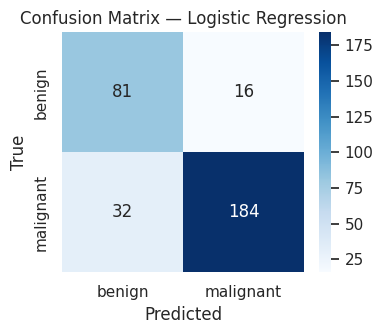

Training Random Forest ...
--- Random Forest ---
              precision    recall  f1-score   support

      benign       0.94      0.80      0.87        97
   malignant       0.92      0.98      0.95       216

    accuracy                           0.92       313
   macro avg       0.93      0.89      0.91       313
weighted avg       0.92      0.92      0.92       313



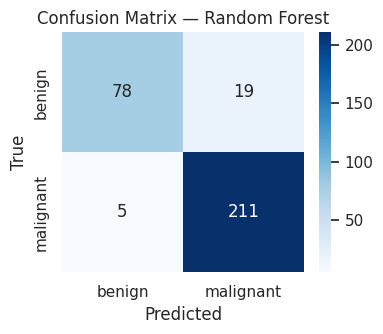

Training SVM ...
--- SVM ---
              precision    recall  f1-score   support

      benign       0.82      0.93      0.87        97
   malignant       0.97      0.91      0.94       216

    accuracy                           0.91       313
   macro avg       0.89      0.92      0.90       313
weighted avg       0.92      0.91      0.92       313



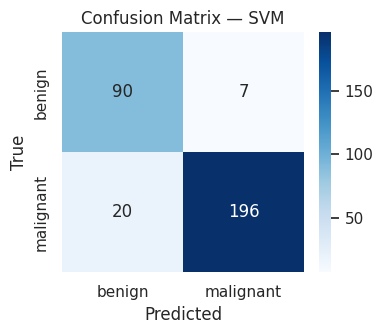

Training XGBoost ...
--- XGBoost ---
              precision    recall  f1-score   support

      benign       0.91      0.90      0.90        97
   malignant       0.95      0.96      0.96       216

    accuracy                           0.94       313
   macro avg       0.93      0.93      0.93       313
weighted avg       0.94      0.94      0.94       313



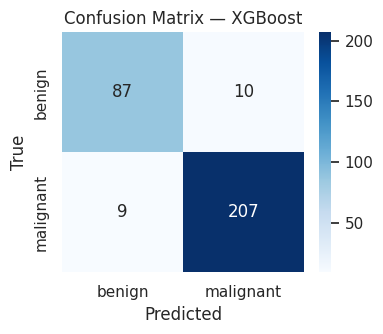

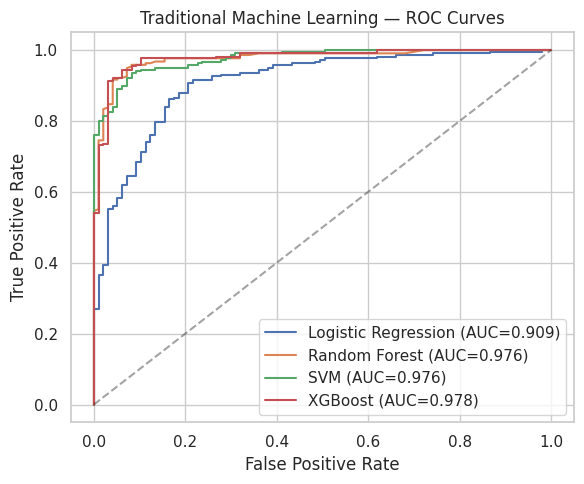

,model,accuracy,precision,recall,f1_score,roc_auc,category
0,Logistic Regression,0.8466,0.8570,0.8466,0.8495,0.9088,Traditional ML
1,Random Forest,0.9233,0.9243,0.9233,0.9215,0.9763,Traditional ML
2,SVM,0.9137,0.9199,0.9137,0.9151,0.9758,Traditional ML
3,XGBoost,0.9393,0.9391,0.9393,0.9392,0.9777,Traditional ML


Traditional ML validation results:


,model,accuracy,precision,recall,f1_score,roc_auc
0,Logistic Regression,0.8558,0.8571,0.8558,0.8564,0.9004
1,Random Forest,0.9103,0.9135,0.9103,0.9071,0.9696
2,SVM,0.9359,0.9359,0.9359,0.9359,0.9845
3,XGBoost,0.9295,0.9296,0.9295,0.9284,0.9711


In [11]:
def train_and_evaluate_sklearn_model(
    model, model_name: str,
    X_train: np.ndarray, y_train: np.ndarray,
    X_test: np.ndarray, y_test: np.ndarray,
    class_names: List[str] = CLASSES,
) -> Tuple[object, Dict[str, float], np.ndarray]:
    """Fit a sklearn-compatible classifier and evaluate it on the test set."""
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else None
    metrics = evaluate_predictions(y_test, y_pred, y_proba, class_names, model_name)
    return model, metrics, y_proba


def run_traditional_ml_comparison(
    models: Dict[str, object],
    X_train: np.ndarray, y_train: np.ndarray,
    X_test: np.ndarray, y_test: np.ndarray,
    class_names: List[str] = CLASSES,
) -> Tuple[pd.DataFrame, Dict[str, object], Dict[str, Tuple[np.ndarray, np.ndarray]]]:
    results, trained_models, roc_data = [], {}, {}
    for name, model in models.items():
        print(f'Training {name} ...')
        fitted, metrics, y_proba = train_and_evaluate_sklearn_model(
            model, name, X_train, y_train, X_test, y_test, class_names
        )
        metrics['category'] = 'Traditional ML'
        results.append(metrics)
        trained_models[name] = fitted
        if y_proba is not None:
            roc_data[name] = (y_test, y_proba)
    return pd.DataFrame(results), trained_models, roc_data


traditional_models = get_traditional_models(seed=RANDOM_STATE)
traditional_results_df, trained_traditional_models, traditional_roc_data = run_traditional_ml_comparison(
    traditional_models, X_train_scaled, y_train, X_test_scaled, y_test, CLASSES
)
plot_roc_curves(traditional_roc_data, title='Traditional Machine Learning — ROC Curves')
display(traditional_results_df.round(4))

# Validation results are retained for model-selection discussion without changing the final test set.
validation_rows = []
for name, model in trained_traditional_models.items():
    row = evaluate_predictions(
        y_val, model.predict(X_val_scaled), model.predict_proba(X_val_scaled)[:, 1],
        CLASSES, model_name=name, plot=False,
    )
    validation_rows.append(row)
classical_validation_results_df = pd.DataFrame(validation_rows)
print('Traditional ML validation results:')
display(classical_validation_results_df.round(4))


### Interpretation of the classical machine-learning results

XGBoost performs best among the four classical models, with 93.93% test accuracy, a weighted F1-score of 0.9392 and ROC-AUC of 0.9777. Random Forest follows with 92.33% accuracy, while SVM reaches 91.37%. Logistic Regression records the lowest accuracy at 84.66%.

The class-specific results add useful context. XGBoost identifies approximately 96% of malignant images and 90% of benign images, giving it a comparatively balanced result. Random Forest achieves about 98% malignant recall but only 80% benign recall, indicating that its stronger recognition of malignant images comes with more benign images being classified incorrectly. SVM shows the opposite tendency, with approximately 93% benign recall and 91% malignant recall.

These findings suggest that nonlinear classifiers are better suited than Logistic Regression to the 20-feature representation used here. However, they do not show that classical machine learning is generally inferior; the result depends on the chosen features, models and dataset split.

## 8. Preparing the deep-learning pipeline

I use the same training, validation and test partitions for the pretrained CNNs and Vision Transformers. A PyTorch dataset reads the image files and supplies the corresponding labels in batches.

The deep-learning models differ from the classical classifiers because they learn image representations from the pixels rather than relying on the 20 handcrafted descriptors. I use pretrained weights and adapt the final classification layer to the two classes in this study.

In [12]:
class HistopathologyDataset(Dataset):
    """PyTorch Dataset wrapping a DataFrame of [path, label] rows."""

    def __init__(self, df: pd.DataFrame, transform: Callable, label_map: Dict[str, int] = LABEL_MAP):
        self.paths = df['path'].tolist()
        self.labels = df['label'].map(label_map).tolist()
        self.transform = transform

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, idx: int):
        img = Image.open(self.paths[idx]).convert('RGB')
        img = self.transform(img)
        label = self.labels[idx]
        return img, label


def get_transforms(image_size: int = 224, train: bool = True) -> T.Compose:
    """Return torchvision transforms; training set gets light augmentation."""
    normalize = T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    if train:
        return T.Compose([
            T.Resize((image_size, image_size)),
            T.RandomHorizontalFlip(),
            T.RandomVerticalFlip(),
            T.RandomRotation(20),
            T.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
            T.ToTensor(),
            normalize,
        ])
    return T.Compose([
        T.Resize((image_size, image_size)),
        T.ToTensor(),
        normalize,
    ])


def get_dataloaders(
    train_df: pd.DataFrame, val_df: pd.DataFrame, test_df: pd.DataFrame,
    image_size: int = 224, batch_size: int = 32, num_workers: int = 0,
) -> Tuple[DataLoader, DataLoader, DataLoader]:
    """Build train/val/test DataLoaders with appropriate transforms."""
    train_ds = HistopathologyDataset(train_df, get_transforms(image_size, train=True))
    val_ds = HistopathologyDataset(val_df, get_transforms(image_size, train=False))
    test_ds = HistopathologyDataset(test_df, get_transforms(image_size, train=False))

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
    return train_loader, val_loader, test_loader


IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_EPOCHS = 10  # Maximum budget; early stopping may finish sooner
EARLY_STOPPING_PATIENCE = 3
EARLY_STOPPING_MIN_DELTA = 1e-4
LEARNING_RATE = 1e-4

train_loader, val_loader, test_loader = get_dataloaders(
    train_df, val_df, test_df, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, num_workers=0
)
print('Batches — train:', len(train_loader), 'val:', len(val_loader), 'test:', len(test_loader))

Batches — train: 46 val: 10 test: 10


### Preprocessing images for pretrained models

I resize the images to 224 × 224 pixels and apply the transformations defined in the PyTorch pipeline. The same data partitions are used for the CNN and Transformer experiments.

Keeping the input dimensions and evaluation data consistent helps make the results comparable, although differences in architecture, pretrained weights and training behaviour can still affect performance.

### Model training and checkpoint selection

I fine-tune the pretrained models using AdamW and cross-entropy loss. After each epoch, I evaluate the model on the validation set and record the training and validation losses and accuracies.

I use validation loss to select the checkpoint retained for testing. Early stopping is included to avoid continuing training indefinitely when validation performance stops improving. The training curves help me examine whether improvements on the training images are also reflected in validation performance. Since the models have different architectures, similar training settings do not necessarily imply identical optimisation conditions.

In [13]:
class ValidationLossEarlyStopping:
    """Track significant improvement for patience and absolute minimum for weights."""
    def __init__(self, patience: int = 3, min_delta: float = 1e-4):
        if not isinstance(patience, int) or patience < 1:
            raise ValueError('patience must be a positive integer')
        if not np.isfinite(min_delta) or min_delta < 0:
            raise ValueError('min_delta must be finite and non-negative')
        self.patience = patience
        self.min_delta = min_delta
        self.reference_loss = float('inf')
        self.best_loss = float('inf')
        self.best_state = None
        self.best_epoch = None
        self.bad_epochs = 0

    def update(self, val_loss: float, model: nn.Module, epoch: int) -> bool:
        if not np.isfinite(val_loss):
            raise RuntimeError('Validation loss is non-finite; check inputs and optimisation.')
        # Save every absolute minimum, even below the patience improvement threshold.
        if val_loss < self.best_loss:
            self.best_loss = val_loss
            self.best_epoch = epoch
            self.best_state = {
                k: v.detach().cpu().clone() for k, v in model.state_dict().items()
            }
        if val_loss < self.reference_loss - self.min_delta:
            self.reference_loss = val_loss
            self.bad_epochs = 0
        else:
            self.bad_epochs += 1
        return self.bad_epochs >= self.patience

    def restore(self, model: nn.Module) -> None:
        if self.best_state is None:
            raise RuntimeError('No valid validation checkpoint was recorded.')
        model.load_state_dict(self.best_state)


def build_deep_model(model_name: str, num_classes: int = 2, pretrained: bool = True) -> nn.Module:
    """Create a pretrained timm CNN or Transformer with a fresh classification head."""
    return timm.create_model(model_name, pretrained=pretrained, num_classes=num_classes)


def train_model(
    model: nn.Module, train_loader: DataLoader, val_loader: DataLoader,
    num_epochs: int = 10, lr: float = 1e-4, device: torch.device = DEVICE,
    model_name: str = 'model', weight_decay: float = 1e-4,
    patience: int = 3, min_delta: float = 1e-4,
) -> Tuple[nn.Module, Dict[str, List[float]]]:
    """
    Fine-tune a classification model with AdamW + mixed precision.
    Stops on validation-loss stagnation and restores minimum-loss weights.
    """
    if num_epochs < 1:
        raise ValueError('num_epochs must be positive')
    if len(train_loader) == 0 or len(val_loader) == 0:
        raise ValueError('Training and validation loaders must be non-empty')
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
    criterion = nn.CrossEntropyLoss()
    scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    early_stopper = ValidationLossEarlyStopping(patience, min_delta)
    stopped_early = False

    for epoch in range(num_epochs):
        model.train()
        running_loss, running_correct, n_samples = 0.0, 0, 0
        pbar = tqdm(train_loader, desc=f'[{model_name}] Epoch {epoch + 1}/{num_epochs} (train)')
        for imgs, labels in pbar:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
                outputs = model(imgs)
                loss = criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * imgs.size(0)
            running_correct += (outputs.argmax(1) == labels).sum().item()
            n_samples += imgs.size(0)
            pbar.set_postfix(loss=running_loss / n_samples, acc=running_correct / n_samples)

        train_loss = running_loss / n_samples
        train_acc = running_correct / n_samples

        model.eval()
        val_loss, val_correct, n_val = 0.0, 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = model(imgs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * imgs.size(0)
                val_correct += (outputs.argmax(1) == labels).sum().item()
                n_val += imgs.size(0)
        val_loss /= n_val
        val_acc = val_correct / n_val
        scheduler.step()

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        print(f'[{model_name}] Epoch {epoch + 1}: train_loss={train_loss:.4f} train_acc={train_acc:.4f} '
              f'val_loss={val_loss:.4f} val_acc={val_acc:.4f}')

        if early_stopper.update(val_loss, model, epoch + 1):
            stopped_early = True
            print(f'[{model_name}] Early stopping at epoch {epoch + 1}: '
                  f'no significant validation-loss improvement for {patience} epochs.')
            break

    early_stopper.restore(model)
    model.training_summary = {
        'monitor': 'val_loss', 'patience': patience, 'min_delta': min_delta,
        'epochs_run': len(history['val_loss']), 'stopped_early': stopped_early,
        'best_epoch': early_stopper.best_epoch,
        'best_val_loss': early_stopper.best_loss,
    }
    print(f'[{model_name}] Restored epoch {early_stopper.best_epoch}; '
          f'best val_loss={early_stopper.best_loss:.6f}; '
          f'epochs run={len(history["val_loss"])}.')
    return model, history


def plot_training_history(history: Dict[str, List[float]], model_name: str = 'Model') -> None:
    """Plot loss and accuracy curves for train/val."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    epochs = range(1, len(history['train_loss']) + 1)
    axes[0].plot(epochs, history['train_loss'], label='train')
    axes[0].plot(epochs, history['val_loss'], label='val')
    axes[0].set_title(f'{model_name} — Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()

    axes[1].plot(epochs, history['train_acc'], label='train')
    axes[1].plot(epochs, history['val_acc'], label='val')
    axes[1].set_title(f'{model_name} — Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].legend()
    plt.tight_layout()
    plt.show()



=== Fine-tuning MobileNetV2 (mobilenetv2_100) ===


model.safetensors: reconstructing file:   0%|          |  0.00B / 14.2MB            

model.safetensors: downloading bytes:           |  0.00B            

[MobileNetV2] Epoch 1/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

[MobileNetV2] Epoch 1: train_loss=2.0215 train_acc=0.6126 val_loss=0.6527 val_acc=0.8269


[MobileNetV2] Epoch 2/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

... (13 outputs left out)

[MobileNetV2] Epoch 9/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

[MobileNetV2] Epoch 9: train_loss=0.1906 train_acc=0.9306 val_loss=0.2329 val_acc=0.9199


[MobileNetV2] Epoch 10/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

[MobileNetV2] Epoch 10: train_loss=0.1768 train_acc=0.9430 val_loss=0.2156 val_acc=0.9359
[MobileNetV2] Restored epoch 10; best val_loss=0.215613; epochs run=10.


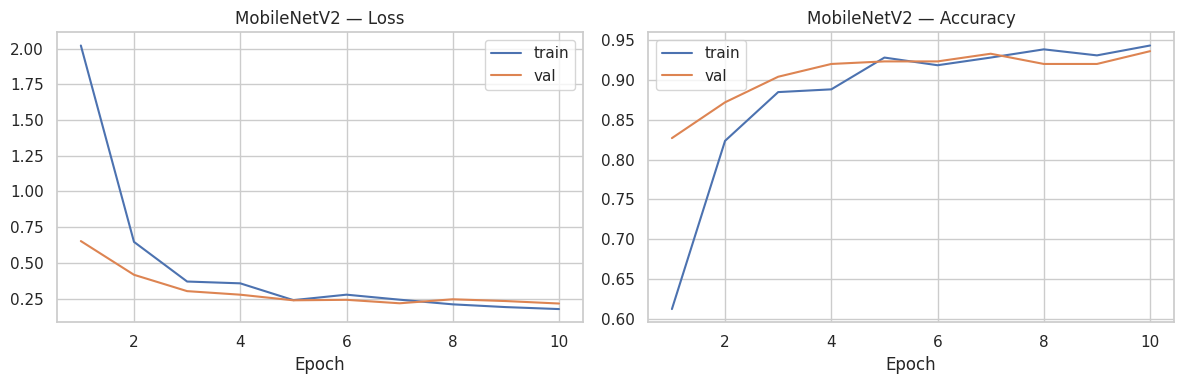

--- MobileNetV2 ---
              precision    recall  f1-score   support

      benign       0.82      0.92      0.87        97
   malignant       0.96      0.91      0.94       216

    accuracy                           0.91       313
   macro avg       0.89      0.91      0.90       313
weighted avg       0.92      0.91      0.91       313



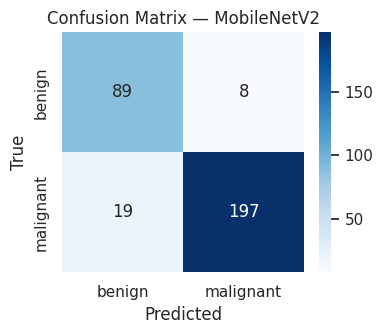


=== Fine-tuning ResNet50 (resnet50) ===


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

[ResNet50] Epoch 1/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

[ResNet50] Epoch 1: train_loss=0.6281 train_acc=0.6806 val_loss=0.6002 val_acc=0.6891


[ResNet50] Epoch 2/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

... (13 outputs left out)

[ResNet50] Epoch 9/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

[ResNet50] Epoch 9: train_loss=0.1960 train_acc=0.9334 val_loss=0.1714 val_acc=0.9455


[ResNet50] Epoch 10/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

[ResNet50] Epoch 10: train_loss=0.1994 train_acc=0.9231 val_loss=0.1653 val_acc=0.9423
[ResNet50] Restored epoch 10; best val_loss=0.165344; epochs run=10.


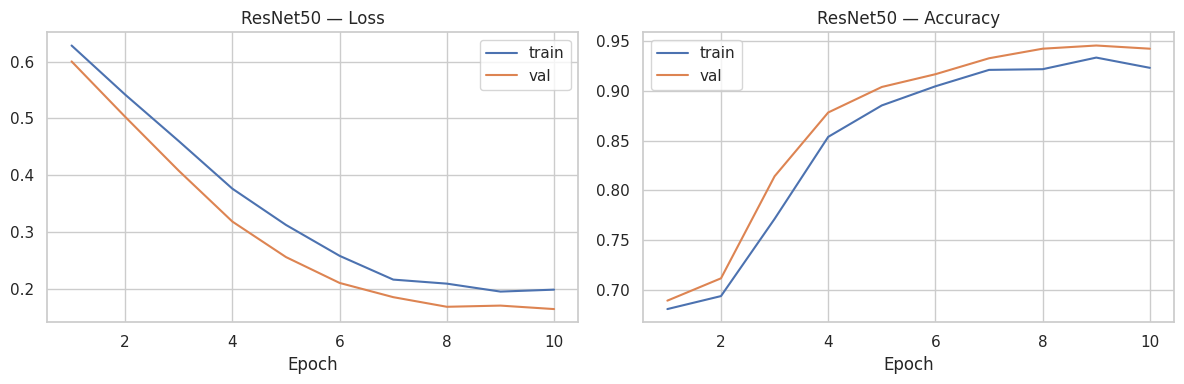

--- ResNet50 ---
              precision    recall  f1-score   support

      benign       0.89      0.88      0.89        97
   malignant       0.94      0.95      0.95       216

    accuracy                           0.93       313
   macro avg       0.92      0.91      0.92       313
weighted avg       0.93      0.93      0.93       313



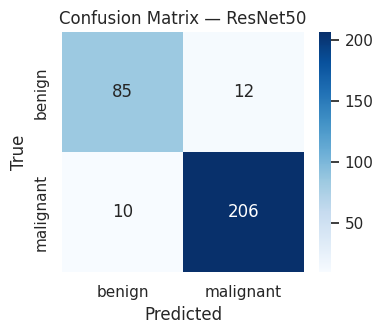


=== Fine-tuning EfficientNetB0 (efficientnet_b0) ===


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

[EfficientNetB0] Epoch 1/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

[EfficientNetB0] Epoch 1: train_loss=1.1801 train_acc=0.7479 val_loss=0.7207 val_acc=0.8173


[EfficientNetB0] Epoch 2/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

... (13 outputs left out)

[EfficientNetB0] Epoch 9/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

[EfficientNetB0] Epoch 9: train_loss=0.1006 train_acc=0.9698 val_loss=0.1645 val_acc=0.9712


[EfficientNetB0] Epoch 10/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

[EfficientNetB0] Epoch 10: train_loss=0.0743 train_acc=0.9746 val_loss=0.1588 val_acc=0.9583
[EfficientNetB0] Restored epoch 10; best val_loss=0.158848; epochs run=10.


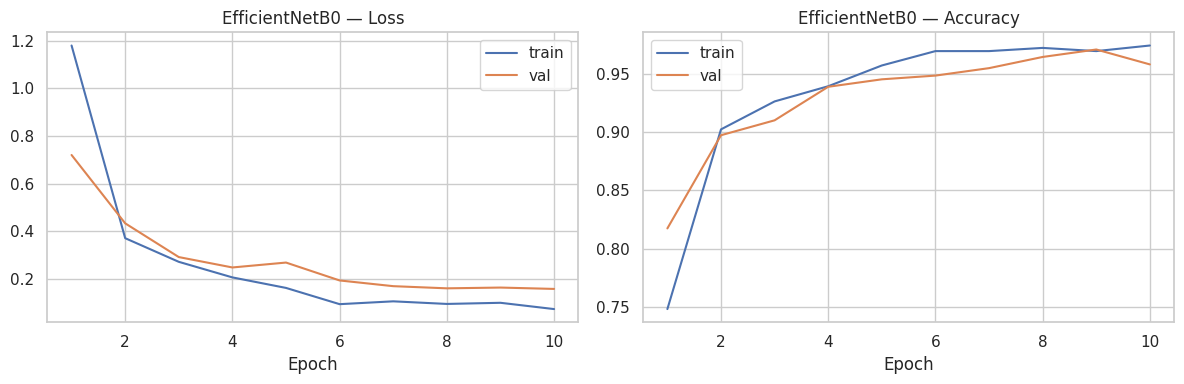

--- EfficientNetB0 ---
              precision    recall  f1-score   support

      benign       0.86      0.97      0.91        97
   malignant       0.99      0.93      0.96       216

    accuracy                           0.94       313
   macro avg       0.92      0.95      0.93       313
weighted avg       0.95      0.94      0.94       313



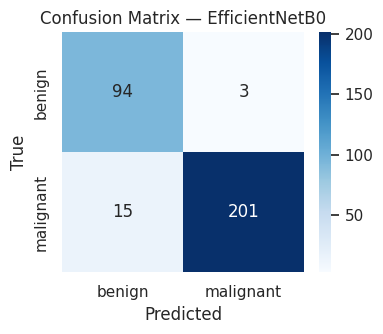

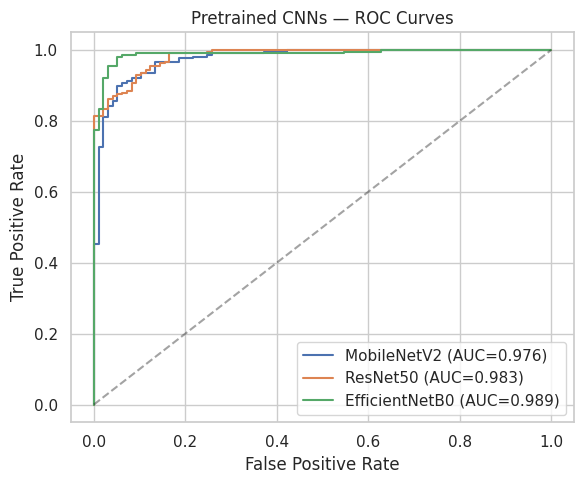

,model,accuracy,precision,recall,f1_score,roc_auc,category
0,MobileNetV2,0.9137,0.9185,0.9137,0.9149,0.9756,Pretrained CNN
1,ResNet50,0.9297,0.9294,0.9297,0.9295,0.9826,Pretrained CNN
2,EfficientNetB0,0.9425,0.9472,0.9425,0.9433,0.9890,Pretrained CNN



=== Fine-tuning ViT Base (vit_base_patch16_224) ===


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

[ViT Base] Epoch 1/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

[ViT Base] Epoch 1: train_loss=0.6879 train_acc=0.6538 val_loss=0.4750 val_acc=0.8077


... (14 outputs left out)

[ViT Base] Epoch 9/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

[ViT Base] Epoch 9: train_loss=0.1620 train_acc=0.9382 val_loss=0.1340 val_acc=0.9615


[ViT Base] Epoch 10/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

[ViT Base] Epoch 10: train_loss=0.1417 train_acc=0.9499 val_loss=0.1328 val_acc=0.9615
[ViT Base] Restored epoch 10; best val_loss=0.132779; epochs run=10.


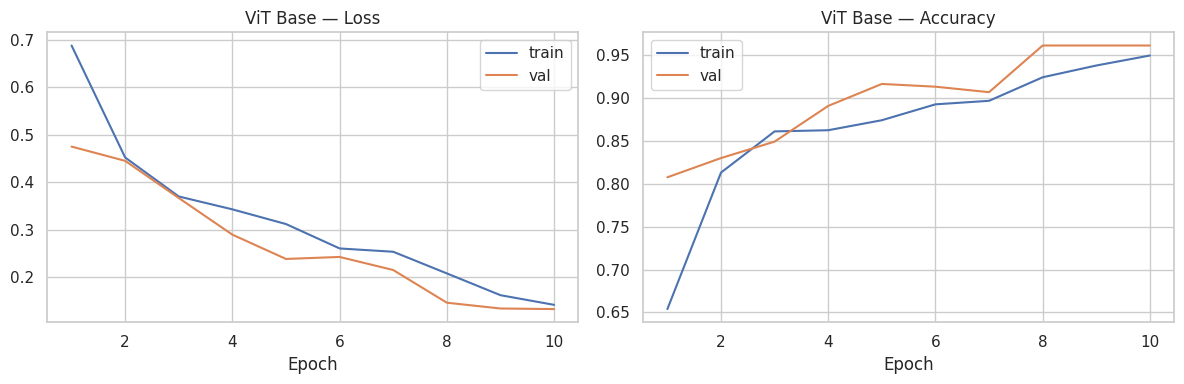

--- ViT Base ---
              precision    recall  f1-score   support

      benign       0.89      0.96      0.93        97
   malignant       0.98      0.95      0.96       216

    accuracy                           0.95       313
   macro avg       0.94      0.95      0.95       313
weighted avg       0.95      0.95      0.95       313



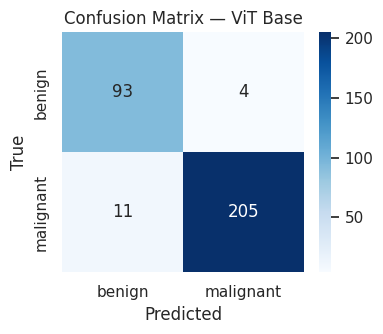


=== Fine-tuning Swin Tiny (swin_tiny_patch4_window7_224) ===


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

[Swin Tiny] Epoch 1/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

[Swin Tiny] Epoch 1: train_loss=0.3920 train_acc=0.8317 val_loss=0.1144 val_acc=0.9615


[Swin Tiny] Epoch 2/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

... (13 outputs left out)

[Swin Tiny] Epoch 9/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

[Swin Tiny] Epoch 9: train_loss=0.0093 train_acc=0.9966 val_loss=0.0415 val_acc=0.9872


[Swin Tiny] Epoch 10/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

[Swin Tiny] Epoch 10: train_loss=0.0079 train_acc=0.9973 val_loss=0.0371 val_acc=0.9936
[Swin Tiny] Restored epoch 8; best val_loss=0.027073; epochs run=10.


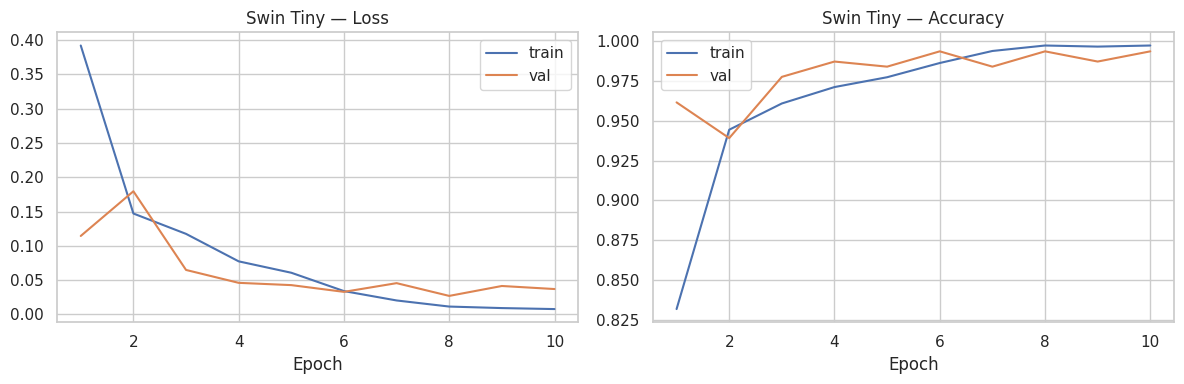

--- Swin Tiny ---
              precision    recall  f1-score   support

      benign       0.99      0.99      0.99        97
   malignant       1.00      1.00      1.00       216

    accuracy                           0.99       313
   macro avg       0.99      0.99      0.99       313
weighted avg       0.99      0.99      0.99       313



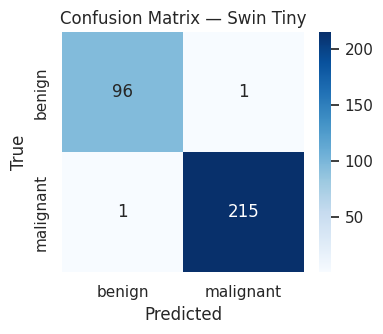


=== Fine-tuning DeiT Small (deit_small_patch16_224) ===


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

[DeiT Small] Epoch 1/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

[DeiT Small] Epoch 1: train_loss=0.4632 train_acc=0.7926 val_loss=0.3012 val_acc=0.8910


[DeiT Small] Epoch 2/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

... (13 outputs left out)

[DeiT Small] Epoch 9/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

[DeiT Small] Epoch 9: train_loss=0.0117 train_acc=0.9966 val_loss=0.0371 val_acc=0.9936


[DeiT Small] Epoch 10/10 (train):   0%|          | 0/46 [00:00<?, ?it/s]

[DeiT Small] Epoch 10: train_loss=0.0098 train_acc=0.9973 val_loss=0.0357 val_acc=0.9936
[DeiT Small] Restored epoch 10; best val_loss=0.035723; epochs run=10.


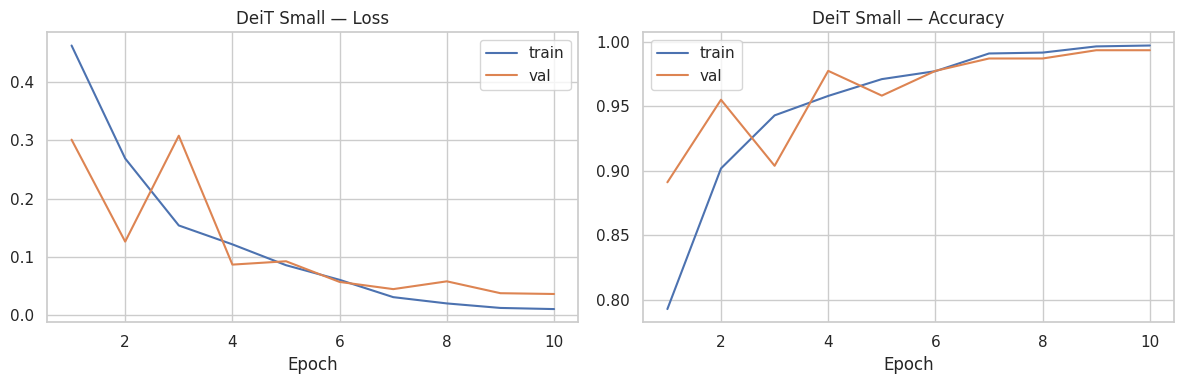

--- DeiT Small ---
              precision    recall  f1-score   support

      benign       0.95      0.99      0.97        97
   malignant       1.00      0.98      0.99       216

    accuracy                           0.98       313
   macro avg       0.97      0.98      0.98       313
weighted avg       0.98      0.98      0.98       313



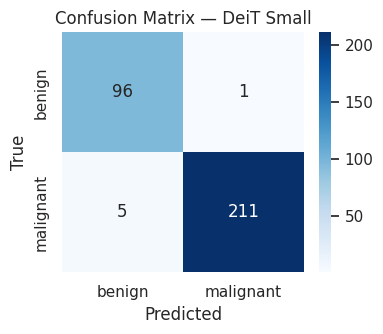

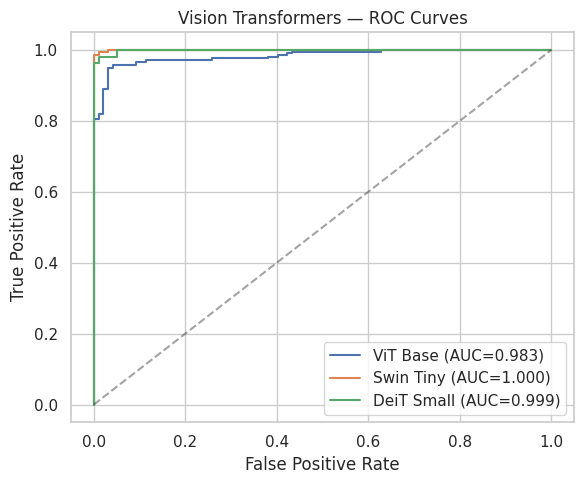

,model,accuracy,precision,recall,f1_score,roc_auc,category
0,ViT Base,0.9521,0.9540,0.9521,0.9525,0.9831,Vision Transformer
1,Swin Tiny,0.9936,0.9936,0.9936,0.9936,0.9998,Vision Transformer
2,DeiT Small,0.9808,0.9814,0.9808,0.9809,0.9989,Vision Transformer


In [14]:
@torch.no_grad()
def evaluate_deep_model(
    model: nn.Module, data_loader: DataLoader, device: torch.device = DEVICE
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Run inference over a DataLoader. Returns (y_true, y_pred, y_proba_positive_class)."""
    model = model.to(device).eval()
    all_true, all_pred, all_proba = [], [], []
    for imgs, labels in data_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        probs = torch.softmax(outputs, dim=1)[:, 1].cpu().numpy()
        preds = outputs.argmax(1).cpu().numpy()
        all_true.append(labels.numpy())
        all_pred.append(preds)
        all_proba.append(probs)
    return np.concatenate(all_true), np.concatenate(all_pred), np.concatenate(all_proba)


def run_deep_model_comparison(
    model_specs: Dict[str, str], category: str,
    train_loader: DataLoader, val_loader: DataLoader, test_loader: DataLoader,
    num_epochs: int = 10, lr: float = 1e-4, device: torch.device = DEVICE,
    class_names: List[str] = CLASSES,
    patience: int = 3, min_delta: float = 1e-4,
) -> Tuple[pd.DataFrame, Dict[str, nn.Module], Dict[str, Dict], Dict[str, Tuple[np.ndarray, np.ndarray]]]:
    """Fine-tune and evaluate a dictionary of pretrained deep-learning models."""
    results, trained_models, histories, roc_data = [], {}, {}, {}
    for display_name, timm_name in model_specs.items():
        print(f'\n=== Fine-tuning {display_name} ({timm_name}) ===')
        model = build_deep_model(timm_name, num_classes=len(class_names), pretrained=True)
        model, history = train_model(
            model, train_loader, val_loader, num_epochs=num_epochs, lr=lr,
            device=device, model_name=display_name,
            patience=patience, min_delta=min_delta,
        )
        plot_training_history(history, model_name=display_name)

        y_true, y_pred, y_proba = evaluate_deep_model(model, test_loader, device)
        metrics = evaluate_predictions(
            y_true, y_pred, y_proba, class_names, model_name=display_name
        )
        metrics['category'] = category
        results.append(metrics)
        trained_models[display_name] = model
        histories[display_name] = history
        roc_data[display_name] = (y_true, y_proba)

    return pd.DataFrame(results), trained_models, histories, roc_data


CNN_MODEL_SPECS = {
    'MobileNetV2': 'mobilenetv2_100',
    'ResNet50': 'resnet50',
    'EfficientNetB0': 'efficientnet_b0',
}

cnn_results_df, trained_cnn_models, cnn_histories, cnn_roc_data = run_deep_model_comparison(
    CNN_MODEL_SPECS, 'Pretrained CNN', train_loader, val_loader, test_loader,
    num_epochs=NUM_EPOCHS, lr=LEARNING_RATE, device=DEVICE, class_names=CLASSES,
    patience=EARLY_STOPPING_PATIENCE, min_delta=EARLY_STOPPING_MIN_DELTA,
)
plot_roc_curves(cnn_roc_data, title='Pretrained CNNs — ROC Curves')
display(cnn_results_df.round(4))


TRANSFORMER_MODEL_SPECS = {
    'ViT Base': 'vit_base_patch16_224',
    'Swin Tiny': 'swin_tiny_patch4_window7_224',
    'DeiT Small': 'deit_small_patch16_224',
}

transformer_results_df, trained_transformer_models, transformer_histories, transformer_roc_data = run_deep_model_comparison(
    TRANSFORMER_MODEL_SPECS, 'Vision Transformer', train_loader, val_loader, test_loader,
    num_epochs=NUM_EPOCHS, lr=LEARNING_RATE, device=DEVICE, class_names=CLASSES,
    patience=EARLY_STOPPING_PATIENCE, min_delta=EARLY_STOPPING_MIN_DELTA,
)
plot_roc_curves(transformer_roc_data, title='Vision Transformers — ROC Curves')
display(transformer_results_df.round(4))


### Interpretation of pretrained CNN and Vision Transformer results

Among the pretrained CNNs, EfficientNetB0 gives the strongest result, with 94.25% accuracy, a weighted F1-score of 0.9433 and ROC-AUC of 0.9890. ResNet50 achieves 92.97% accuracy, while MobileNetV2 reaches 91.37%. EfficientNetB0 recognises approximately 97% of benign images but about 93% of malignant images, showing that its overall score does not imply equally high recall for both classes.

The Vision Transformers perform particularly well on this test set. Swin Tiny achieves 99.36% accuracy, a weighted F1-score of 0.9936 and ROC-AUC of 0.9998. DeiT Small follows with 98.08% accuracy and ViT Base with 95.21%. Swin Tiny also shows approximately 99% recall for benign images and near-perfect recall for malignant images in the displayed classification report.

The training histories show that validation performance generally improves during fine-tuning, although losses fluctuate across epochs. For example, Swin Tiny's lowest recorded validation loss occurs at epoch 8, and the corresponding checkpoint is restored. Its strong test result is encouraging, but it should not be interpreted as evidence that the architecture will achieve the same accuracy on independent patient cohorts or images from other laboratories.

## 9. Comparing all ten models

I combine the results of the four classical classifiers, three pretrained CNNs and three Vision Transformers into one table. Each model is assessed on the same 313 test images using the evaluation metrics defined earlier.

I sort the table by weighted F1-score and plot F1 and ROC-AUC to compare the models. The ranking describes performance on this test partition; it does not replace a broader assessment of class-specific errors, reproducibility and generalisation.

In [15]:
def compile_results_table(*result_dfs: pd.DataFrame) -> pd.DataFrame:
    """Concatenate multiple results DataFrames and sort by F1 score (descending)."""
    combined = pd.concat(result_dfs, ignore_index=True)
    combined = combined.sort_values('f1_score', ascending=False).reset_index(drop=True)
    return combined


def plot_model_comparison(results_df: pd.DataFrame, metric: str = 'f1_score') -> None:
    """Bar chart comparing all models on a given metric, colored by category."""
    ordered = results_df.sort_values(metric, ascending=False)
    plt.figure(figsize=(10, max(4, 0.4 * len(ordered))))
    sns.barplot(data=ordered, y='model', x=metric, hue='category', dodge=False)
    plt.title(f'Model Comparison — {metric}')
    plt.xlabel(metric)
    plt.ylabel('')
    plt.tight_layout()
    plt.show()


final_results_df = compile_results_table(traditional_results_df, cnn_results_df, transformer_results_df)
display(final_results_df[['model', 'category', 'accuracy', 'precision', 'recall', 'f1_score', 'roc_auc']])


,model,category,accuracy,precision,recall,f1_score,roc_auc
0,Swin Tiny,Vision Transformer,0.993610,0.993610,0.993610,0.993610,0.999761
1,DeiT Small,Vision Transformer,0.980831,0.981403,0.980831,0.980935,0.998855
2,ViT Base,Vision Transformer,0.952077,0.954014,0.952077,0.952517,0.983104
3,EfficientNetB0,Pretrained CNN,0.942492,0.947204,0.942492,0.943345,0.988975
4,XGBoost,Traditional ML,0.939297,0.939145,0.939297,0.939210,0.977663
5,ResNet50,Pretrained CNN,0.929712,0.929392,0.929712,0.929508,0.982579
6,Random Forest,Traditional ML,0.923323,0.924323,0.923323,0.921544,0.976303
7,SVM,Traditional ML,0.913738,0.919857,0.913738,0.915109,0.975754
8,MobileNetV2,Pretrained CNN,0.913738,0.918549,0.913738,0.914925,0.975563
9,Logistic Regression,Traditional ML,0.846645,0.857032,0.846645,0.849538,0.908839


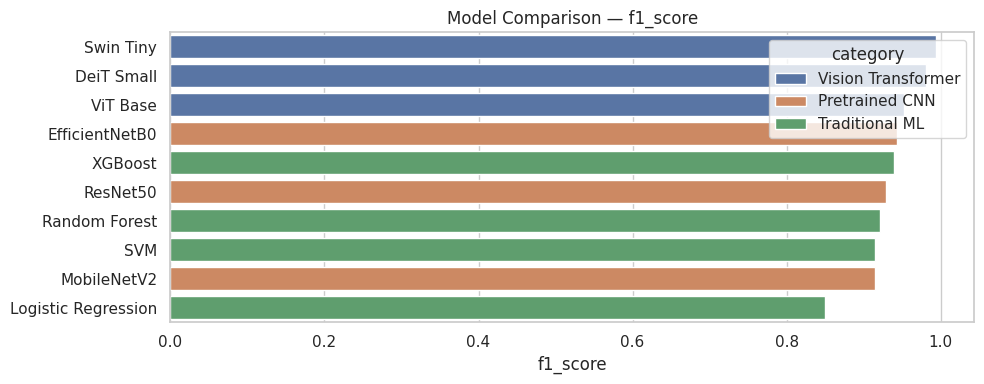

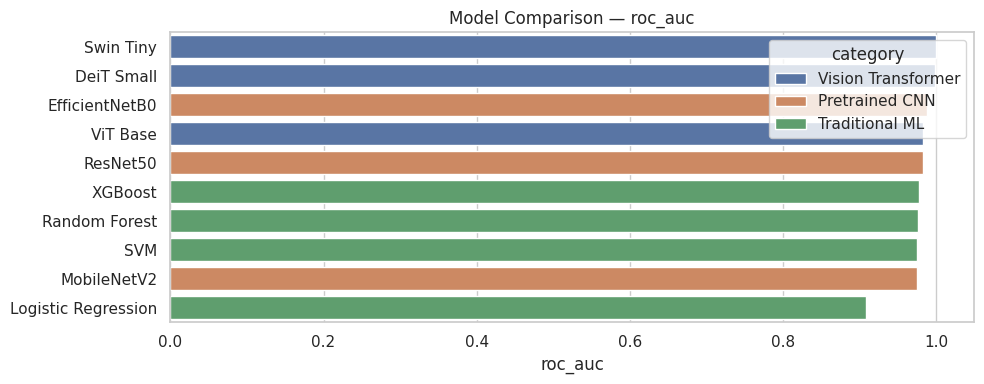


Best model overall (by F1):


,0
model,Swin Tiny
accuracy,0.99361
precision,0.99361
recall,0.99361
f1_score,0.99361
roc_auc,0.999761
category,Vision Transformer


In [16]:
plot_model_comparison(final_results_df, metric='f1_score')
plot_model_comparison(final_results_df, metric='roc_auc')

print('\nBest model overall (by F1):')
final_results_df.iloc[0]

### Interpretation of the overall model comparison

Swin Tiny ranks first, with a weighted F1-score of 0.9936 and ROC-AUC of 0.9998. DeiT Small is second (F1 = 0.9809), followed by ViT Base (0.9525). The best CNN, EfficientNetB0, achieves an F1-score of 0.9433, while XGBoost is the strongest classical classifier at 0.9392.

The results therefore favour the Vision Transformers on this particular split. However, the difference between EfficientNetB0 and XGBoost is small, despite their very different feature-learning approaches. This suggests that the compact colour and texture descriptors remain a competitive baseline for the selected dataset.

I also note that the overall ranking is based on weighted F1, not malignant sensitivity alone. For example, Random Forest records approximately 98% malignant recall despite ranking below several other models by weighted F1. The confusion matrices are therefore necessary when considering the type of errors each model makes.

Swin Tiny's very high performance warrants further checking, particularly because the partition was made at image level. Related images appearing across training and testing could make the task easier than classifying images from unseen patients. The present results support a comparison within this experiment, not a claim of clinical readiness.

## 10. Discussion and conclusion

I compared ten models across three approaches to breast histopathology classification. The classical classifiers used 20 handcrafted colour and texture features, whereas the pretrained CNNs and Vision Transformers learned their representations from the image inputs.

XGBoost was the strongest traditional classifier, achieving 93.93% accuracy and a weighted F1-score of 0.9392. EfficientNetB0 led the pretrained CNNs with 94.25% accuracy and F1 of 0.9433. Swin Tiny was the best-performing model overall, reaching 99.36% accuracy and F1 of 0.9936, followed by DeiT Small and ViT Base.

The findings indicate that the pretrained Vision Transformers, particularly Swin Tiny, performed better than the selected CNN and handcrafted-feature baselines on the held-out images. At the same time, the performance of XGBoost shows that a comparatively simple feature-based approach can remain competitive, especially when computational resources are limited.

I interpret these findings cautiously. The evaluation uses one image-level split of 100X images, without confirmed patient-level separation or external validation. The class imbalance also makes it necessary to consider malignant and benign recall alongside aggregate scores. Further work should assess patient-independent splits, repeated experiments and external datasets before drawing stronger conclusions about generalisation or potential clinical use.